# 04 Test evaluation and ranking performance — XGBoost round2
Load the model produced by notebook 03. Evaluate its fixed scores on the test records,
then summarize selection at **@10%, @20%, …, @100%**. No fitting, tuning or model reselection.
This reproduces an evaluation of the already-inspected test set; it is not a new independent validation.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, xgboost
from IPython.display import display
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, classification_report

PROJECT_ROOT = None  # Set Path(r"/path/to/final project") if opened outside the project.
if PROJECT_ROOT is None:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "data/processed/cardio_train_80.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing data/ and predictive_analytics/.")
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
NOTEBOOK_DIR = PROJECT_ROOT / "predictive_analytics"
sys.path.insert(0, str(NOTEBOOK_DIR))
from training_utils import FEATURES, NUMERIC, CATEGORIES, evaluate, sha

RUN_NAME = "seven_features_run_01"  # Same run used in notebooks 01–03.
EVALUATION_NAME = "xgboost_round2_test_01"  # Use a new name for an explicit new evaluation export.
RUN_DIR = NOTEBOOK_DIR / "runs" / RUN_NAME
MODEL_DIR = RUN_DIR / "03_round2/xgboost"
OUTPUT_DIR = RUN_DIR / "04_test_and_ranking" / EVALUATION_NAME
THRESHOLD = 0.5
CAPACITY_PERCENTAGES = list(range(10, 101, 10))
SEED = 4145
print("Kernel:", sys.executable)
print("Output:", OUTPUT_DIR)


Kernel: /Users/liujueshan/Desktop/comp4145/final project/.venv/bin/python
Output: /Users/liujueshan/Desktop/comp4145/final project/predictive_analytics/runs/seven_features_run_01/04_test_and_ranking/xgboost_round2_test_01


## Load the selected model and freeze the evaluation settings
The selected parameters are read from the current notebook run, not from historical reports.
The final test set must not be used to refit preprocessing or choose hyperparameters/thresholds.


In [2]:
if not (RUN_DIR / "03_round2/complete.json").exists():
    raise FileNotFoundError("Finish notebook 03 with the same RUN_NAME first.")
metadata = json.loads((MODEL_DIR / "metadata.json").read_text())
bundle = joblib.load(MODEL_DIR / "model_pipeline.joblib")
pipeline = bundle["pipeline"]
assert bundle["features"] == FEATURES and metadata["parameters"] == bundle["parameters"]
assert bundle["threshold"] == THRESHOLD
assert metadata["data_protocol"]["seed"] == SEED
assert sha(PROJECT_ROOT / "data/processed/cardio_train_80.csv") == metadata["data_protocol"]["training_sha256"]
assert all(pipeline.named_steps["classifier"].get_params()[k] == v for k, v in bundle["parameters"].items())
MODEL_SHA_BEFORE = sha(MODEL_DIR / "model_pipeline.joblib")
display(pd.DataFrame([{"Parameter": k, "Selected value": repr(v)}
    for k, v in bundle["parameters"].items()]).style.hide(axis="index"))

if OUTPUT_DIR.exists():
    raise FileExistsError("Existing test output is protected. View the saved results, or explicitly set a new EVALUATION_NAME.")
OUTPUT_DIR.mkdir(parents=True)
evaluation_plan = {
    "model": "XGBoost round2", "model_sha256": MODEL_SHA_BEFORE,
    "parameters": bundle["parameters"], "features": FEATURES, "threshold": THRESHOLD,
    "capacity_percentages": CAPACITY_PERCENTAGES, "seed": SEED,
    "tie_rule": "descending score; SHA256(seed:id) breaks score ties without labels",
    "test_previously_evaluated": True, "fit_performed": False,
}
(OUTPUT_DIR / "evaluation_plan.json").write_text(json.dumps(evaluation_plan, indent=2))


Parameter,Selected value
n_estimators,300
max_depth,3
min_child_weight,5
learning_rate,0.05
subsample,0.6
colsample_bytree,0.8
reg_lambda,1.0
objective,'binary:logistic'
eval_metric,'logloss'
tree_method,'hist'


863

## Prepare seven test inputs
`cardio` is retained as the evaluation answer but excluded from the feature matrix.
The existing MinMax encoding is reversed; numeric values are checked against source records.
The saved pipeline applies its development-fitted preprocessing via `predict_proba`.


In [3]:
DATA_DIR = PROJECT_ROOT / "data/processed"
TEST_PATH = DATA_DIR / "cardio_test_20.csv"
EXPECTED_TEST_SHA = "26528e69d13881084ea2960f637628f1ca47f2b94246018b7093600b9a76a723"
assert sha(TEST_PATH) == EXPECTED_TEST_SHA, "Review the evaluation protocol for a changed test dataset."
test = pd.read_csv(TEST_PATH, float_precision="round_trip")
ids = test["id"].to_numpy()
development_ids = pd.read_csv(DATA_DIR / "cardio_train_80.csv", usecols=["id"])["id"].to_numpy()
assert len(test) == 13714 and len(np.unique(ids)) == len(ids)
assert not set(ids) & set(development_ids)
adapter = bundle["denormalization_params"]

def extract_seven_inputs(frame):
    values = {c: frame[c].to_numpy(float) * (adapter[c]["max"] - adapter[c]["min"]) + adapter[c]["min"]
              for c in NUMERIC}
    values["gender"] = frame["gender"].to_numpy(int) + 1
    for c in ["cholesterol", "gluc"]:
        flags = np.column_stack([frame[f"{c}_{level}"].astype(str).str.lower()
            .isin(["true", "1", "1.0"]).to_numpy() for level in [1, 2, 3]])
        assert np.all(flags.sum(axis=1) == 1)
        values[c] = flags.argmax(axis=1) + 1
    return np.column_stack([values[c] for c in FEATURES]).astype(float)

X_test = extract_seven_inputs(test)
assert np.array_equal(X_test, extract_seven_inputs(test.drop(columns="cardio")))
flipped_labels = test.assign(cardio=1 - test["cardio"])
assert np.array_equal(X_test, extract_seven_inputs(flipped_labels))
raw_all = pd.read_csv(PROJECT_ROOT / "data/raw/cardio_train.csv", sep=";").set_index("id")
raw_test = raw_all.loc[ids].reset_index()
canonical = pd.DataFrame({
    "age_years": raw_test["age"] / 365.25,
    "gender": raw_test["gender"],
    "bmi": raw_test["weight"] / (raw_test["height"] / 100) ** 2,
    "ap_hi": raw_test["ap_hi"], "ap_lo": raw_test["ap_lo"],
    "cholesterol": raw_test["cholesterol"], "gluc": raw_test["gluc"],
})[FEATURES]
assert np.allclose(X_test, canonical.to_numpy(float), rtol=0, atol=1e-8)
X_test = canonical.to_numpy(float)
assert X_test.shape == (13714, 7) and np.isfinite(X_test).all()
assert "cardio" not in FEATURES and "id" not in FEATURES
display(canonical.head())
print("Test records:", len(X_test), "| Model input columns:", FEATURES)


,age_years,gender,bmi,ap_hi,ap_lo,cholesterol,gluc
0,47.759069,2,22.321429,110,70,1,1
1,47.698836,1,44.412661,160,100,1,1
2,56.369610,1,22.230987,120,80,1,1
3,54.674880,1,27.852008,140,90,1,1
4,55.477070,2,27.281746,130,90,1,1


Test records: 13714 | Model input columns: ['age_years', 'gender', 'bmi', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc']


## Generate scores without test-label input


In [4]:
assert np.array_equal(pipeline.classes_, [0, 1])
test_scores = pipeline.predict_proba(X_test)[:, 1]
assert np.isfinite(test_scores).all() and np.all((test_scores >= 0) & (test_scores <= 1))
test_predictions = (test_scores >= THRESHOLD).astype(int)

# Tie-breaking uses ID only after scoring; ID does not enter the model.
tie_keys = [hashlib.sha256(f"{SEED}:{identifier}".encode()).hexdigest() for identifier in ids]
order = np.array(sorted(range(len(ids)), key=lambda i: (-float(test_scores[i]), tie_keys[i])))
assert np.all(np.diff(test_scores[order]) <= 0)

# Only now use the held-out answers to evaluate the already-fixed scores and ordering.
y_test = test["cardio"].to_numpy(int)
assert np.array_equal(y_test, raw_test["cardio"].to_numpy(int))
N, POSITIVES = len(y_test), int(y_test.sum())
NEGATIVES = N - POSITIVES
PREVALENCE = POSITIVES / N
assert (N, POSITIVES, NEGATIVES) == (13714, 6784, 6930)
pd.DataFrame({"id": ids, "predicted_score": test_scores, "predicted_cardio": test_predictions})    .to_csv(OUTPUT_DIR / "test_scores_without_truth.csv", index=False)
print(f"Test labels: 0={NEGATIVES:,}; 1={POSITIVES:,}")


Test labels: 0=6,930; 1=6,784


## Overall test evaluation
Classification metrics use the fixed score threshold 0.5. ROC-AUC and Average Precision
use continuous scores. The development column is a CV mean, not a second test result.


In [5]:
test_metrics = evaluate(y_test, test_scores)
reported_metrics = ["roc_auc", "accuracy", "precision", "recall", "f1", "specificity", "average_precision"]
evaluation_table = pd.DataFrame([
    {"Metric": metric, "Development CV mean": metadata["summary"][metric], "Test result": test_metrics[metric]}
    for metric in reported_metrics
])
display(evaluation_table.style.hide(axis="index").format({"Development CV mean": "{:.6f}", "Test result": "{:.6f}"}))
display(pd.DataFrame(classification_report(y_test, test_predictions, output_dict=True, zero_division=0)).T.round(4))
evaluation_table.to_csv(OUTPUT_DIR / "test_evaluation_metrics.csv", index=False)
(OUTPUT_DIR / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2))
pd.DataFrame({"id": ids, "actual_cardio": y_test, "predicted_score": test_scores,
              "predicted_cardio": test_predictions}).to_csv(OUTPUT_DIR / "test_scores_with_truth_for_evaluation.csv", index=False)


Metric,Development CV mean,Test result
roc_auc,0.800734,0.793811
accuracy,0.736141,0.727359
precision,0.756089,0.749467
recall,0.688875,0.674233
f1,0.720907,0.709863
specificity,0.782416,0.779365
average_precision,0.782078,0.779073


,precision,recall,f1-score,support
0,0.7096,0.7794,0.7429,6930.0000
1,0.7495,0.6742,0.7099,6784.0000
accuracy,0.7274,0.7274,0.7274,0.7274
macro avg,0.7295,0.7268,0.7264,13714.0000
weighted avg,0.7293,0.7274,0.7265,13714.0000


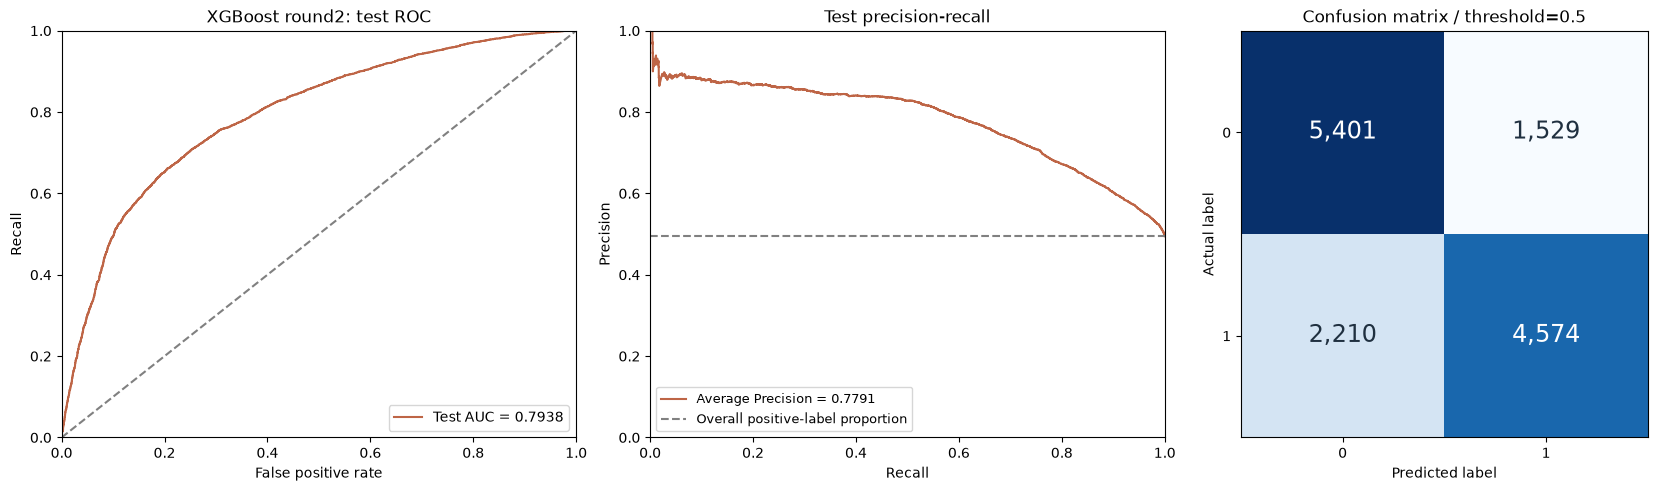

In [6]:
fpr, tpr, _ = roc_curve(y_test, test_scores)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_scores)
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
axes[0].plot(fpr, tpr, label=f'Test AUC = {test_metrics["roc_auc"]:.4f}', color="#BE6546")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="XGBoost round2: test ROC", xlabel="False positive rate", ylabel="Recall", xlim=(0, 1), ylim=(0, 1))
axes[0].legend(loc="lower right")
axes[1].plot(recall_curve, precision_curve, label=f'Average Precision = {test_metrics["average_precision"]:.4f}', color="#BE6546")
axes[1].axhline(PREVALENCE, linestyle="--", color="gray", label="Overall positive-label proportion")
axes[1].set(title="Test precision-recall", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
axes[1].legend(loc="lower left", fontsize=9)
axes[2].imshow(cm, cmap="Blues")
axes[2].set(title="Confusion matrix / threshold=0.5", xlabel="Predicted label", ylabel="Actual label", xticks=[0, 1], yticks=[0, 1])
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f"{cm[i,j]:,}", ha="center", va="center", fontsize=17,
                     color="white" if cm[i,j] > .65 * cm.max() else "#203040")
fig.savefig(OUTPUT_DIR / "test_roc_pr_confusion.png", dpi=180)
plt.show()
pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]).to_csv(OUTPUT_DIR / "test_confusion_matrix.csv")


## Ranking performance at @10% through @100%
Select exactly `ceil(N × percentage / 100)` records. Random expected positive yield is
`selected n × test positive-label proportion`, not a separately observed control group.
Incremental positive yield is an enrichment difference, not a causal or clinical benefit estimate.


In [7]:
capacity_rows = []
for percentage in CAPACITY_PERCENTAGES:
    selected_n = (N * percentage + 99) // 100
    selected = order[:selected_n]
    tp = int(y_test[selected].sum())
    fp, fn = selected_n - tp, POSITIVES - tp
    tn = NEGATIVES - fp
    expected = selected_n * POSITIVES / N
    assert tp + fp + fn + tn == N
    capacity_rows.append({
        "Ranking cutoff": f"@{percentage}%", "Selected n": selected_n,
        "Precision@k": tp / selected_n, "Recall@k": tp / POSITIVES,
        "Lift@k": (tp / selected_n) / PREVALENCE,
        "Positive yield (model)": tp, "Expected positive yield (random)": expected,
        "Incremental positive yield": tp - expected,
        "F1@k": 2 * tp / (selected_n + POSITIVES), "Specificity@k": tn / NEGATIVES,
        "Accuracy@k": (tp + tn) / N, "Boundary score": float(test_scores[selected[-1]]),
        "Boundary ties": int(np.sum(test_scores == test_scores[selected[-1]])),
    })
ranking_performance = pd.DataFrame(capacity_rows)
last = capacity_rows[-1]
assert last["Recall@k"] == 1 and last["Lift@k"] == 1 and last["Incremental positive yield"] == 0
main_columns = ["Ranking cutoff", "Selected n", "Precision@k", "Recall@k", "Lift@k",
                "Positive yield (model)", "Expected positive yield (random)", "Incremental positive yield"]
formatters = {"Selected n": "{:,}", "Precision@k": "{:.2%}", "Recall@k": "{:.2%}",
              "Lift@k": "{:.3f}", "Positive yield (model)": "{:,}",
              "Expected positive yield (random)": "{:,.1f}", "Incremental positive yield": "{:+,.1f}"}
display(ranking_performance[main_columns].style.hide(axis="index").format(formatters)
        .set_properties(**{"white-space": "normal", "text-align": "right"}))
ranking_performance.to_csv(OUTPUT_DIR / "ranking_performance_10_to_100.csv", index=False)
ranking_performance[main_columns].to_html(OUTPUT_DIR / "ranking_performance_10_to_100.html", index=False, float_format=lambda x: f"{x:.6f}")

# Supplementary capacity-based classification metrics: selection is the binary positive rule.
display(ranking_performance[["Ranking cutoff", "F1@k", "Specificity@k", "Accuracy@k"]]
    .style.hide(axis="index").format({"F1@k": "{:.2%}", "Specificity@k": "{:.2%}", "Accuracy@k": "{:.2%}"}))


Ranking cutoff,Selected n,Precision@k,Recall@k,Lift@k,Positive yield (model),Expected positive yield (random),Incremental positive yield
@10%,"1,372",86.95%,17.59%,1.758,"1,193",678.7,+514.3
@20%,"2,743",84.36%,34.11%,1.705,"2,314","1,356.9",+957.1
@30%,"4,115",82.79%,50.22%,1.674,"3,407","2,035.6","+1,371.4"
@40%,"5,486",77.45%,62.63%,1.566,"4,249","2,713.8","+1,535.2"
@50%,"6,857",72.04%,72.82%,1.456,"4,940","3,392.0","+1,548.0"
@60%,"8,229",66.78%,81.00%,1.350,"5,495","4,070.7","+1,424.3"
@70%,"9,600",62.02%,87.77%,1.254,"5,954","4,748.9","+1,205.1"
@80%,"10,972",57.67%,93.28%,1.166,"6,328","5,427.6",+900.4
@90%,"12,343",53.66%,97.63%,1.085,"6,623","6,105.8",+517.2
@100%,"13,714",49.47%,100.00%,1.000,"6,784","6,784.0",+0.0


Ranking cutoff,F1@k,Specificity@k,Accuracy@k
@10%,29.25%,97.42%,57.93%
@20%,48.58%,93.81%,64.28%
@30%,62.52%,89.78%,70.21%
@40%,69.26%,82.15%,72.50%
@50%,72.43%,72.34%,72.58%
@60%,73.20%,60.55%,70.67%
@70%,72.68%,47.39%,67.36%
@80%,71.28%,32.99%,62.81%
@90%,69.25%,17.46%,57.12%
@100%,66.19%,0.00%,49.47%


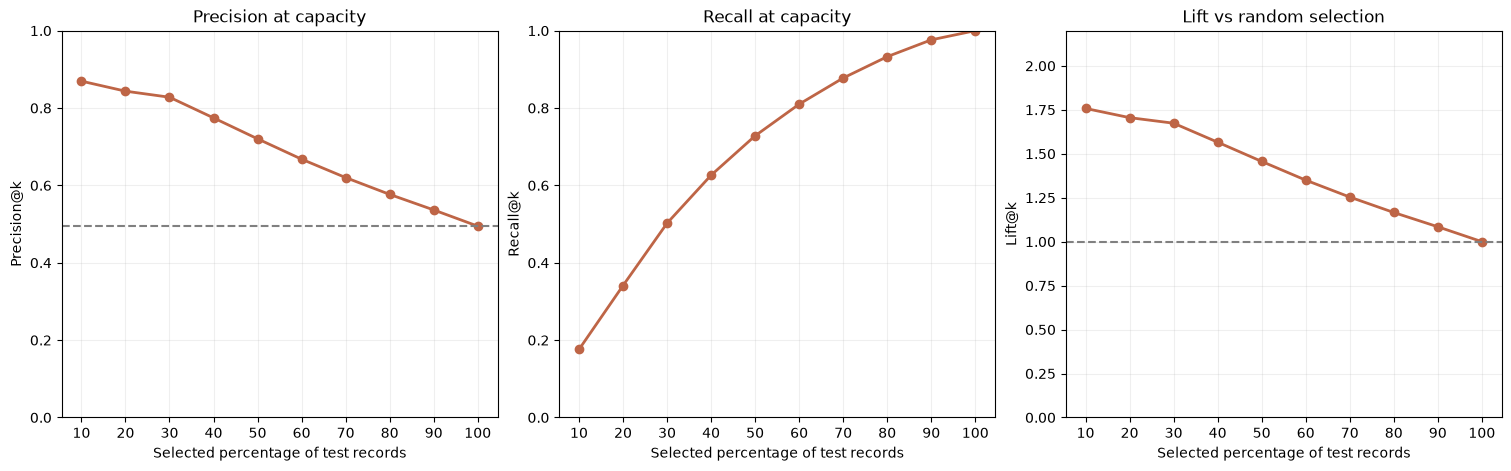

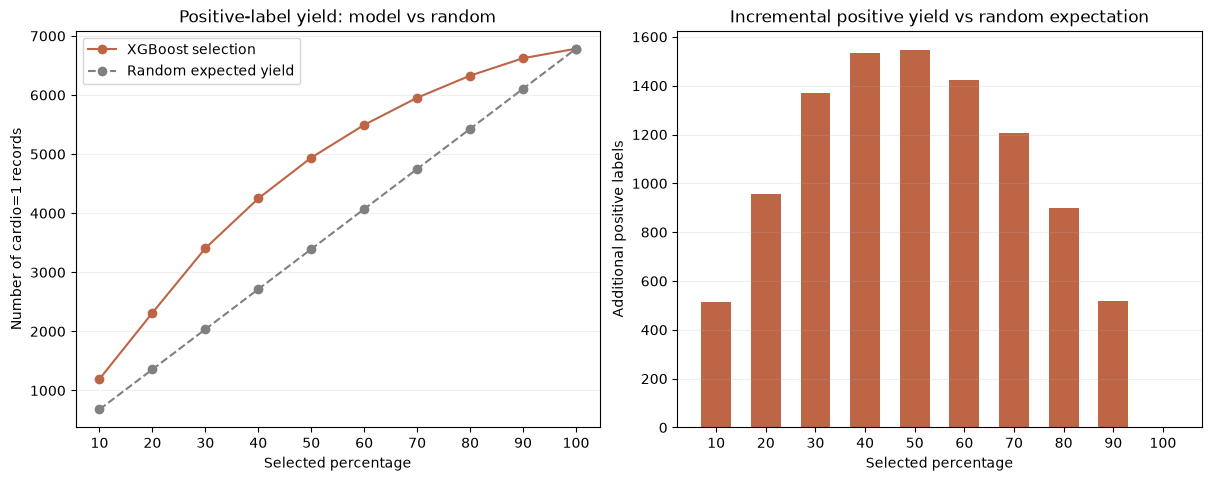

In [8]:
x = CAPACITY_PERCENTAGES
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained")
for ax, metric, title in zip(axes, ["Precision@k", "Recall@k", "Lift@k"],
                           ["Precision at capacity", "Recall at capacity", "Lift vs random selection"]):
    ax.plot(x, ranking_performance[metric], "o-", color="#BE6546", linewidth=2)
    ax.set(title=title, xlabel="Selected percentage of test records", ylabel=metric, xticks=x)
    ax.grid(alpha=.2)
axes[0].set_ylim(0, 1); axes[0].axhline(PREVALENCE, linestyle="--", color="gray")
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 2.2); axes[2].axhline(1, linestyle="--", color="gray")
fig.savefig(OUTPUT_DIR / "ranking_precision_recall_lift.png", dpi=180)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), layout="constrained")
axes[0].plot(x, ranking_performance["Positive yield (model)"], "o-", label="XGBoost selection", color="#BE6546")
axes[0].plot(x, ranking_performance["Expected positive yield (random)"], "o--", label="Random expected yield", color="gray")
axes[0].set(title="Positive-label yield: model vs random", xlabel="Selected percentage", ylabel="Number of cardio=1 records", xticks=x)
axes[0].legend()
axes[1].bar(x, ranking_performance["Incremental positive yield"], width=6, color="#BE6546")
axes[1].set(title="Incremental positive yield vs random expectation", xlabel="Selected percentage", ylabel="Additional positive labels", xticks=x)
for ax in axes: ax.grid(axis="y", alpha=.2)
fig.savefig(OUTPUT_DIR / "ranking_model_vs_random_yield.png", dpi=180)
plt.show()


## Cumulative gain chart: model vs random selection
At each capacity, compare the **cumulative number of actual cardio=1 records** in the
model-ranked list with the expected number from selecting the same number of records
at random. Each pair includes all records up to that percentage, not just that decile.
Random bars are expectations rather than a separately observed control group.
At @100%, both methods include all test positives. Counts illustrate retrospective
label enrichment in a review-prioritization simulation.


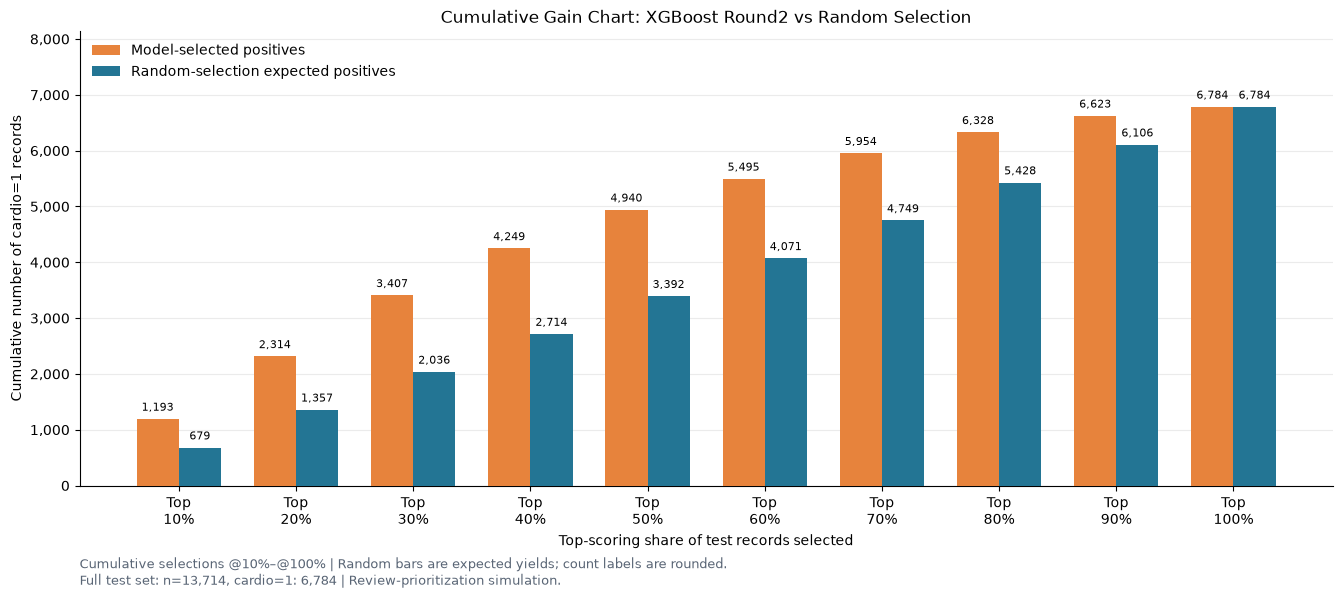

Saved: /Users/liujueshan/Desktop/comp4145/final project/predictive_analytics/runs/seven_features_run_01/04_test_and_ranking/xgboost_round2_test_01/cumulative_gain_model_vs_random_bar.png


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Read the existing ranking results; this cell does not train or score a model.
gain_output_dir = globals().get("OUTPUT_DIR")
if gain_output_dir is None:
    gain_project_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "predictive_analytics").is_dir()), None)
    if gain_project_root is None:
        raise FileNotFoundError("Open this notebook from the project, or run the setup cell first.")
    gain_output_dir = (gain_project_root / "predictive_analytics/runs"
        / globals().get("RUN_NAME", "seven_features_run_01") / "04_test_and_ranking"
        / globals().get("EVALUATION_NAME", "xgboost_round2_test_01"))
gain_output_dir = Path(gain_output_dir)
gain_table = pd.read_csv(gain_output_dir / "ranking_performance_10_to_100.csv")
gain_model = gain_table["Positive yield (model)"].to_numpy()
gain_random = gain_table["Expected positive yield (random)"].to_numpy()
gain_positions = np.arange(len(gain_table))
gain_labels = ["Top\n" + str(value).lstrip("@") for value in gain_table["Ranking cutoff"]]
assert np.isclose(gain_model[-1], gain_random[-1])

gain_fig, gain_ax = plt.subplots(figsize=(14, 6.4))
gain_width = 0.36
model_bars = gain_ax.bar(gain_positions - gain_width / 2, gain_model, gain_width,
    label="Model-selected positives", color="#E7833C", zorder=3)
random_bars = gain_ax.bar(gain_positions + gain_width / 2, gain_random, gain_width,
    label="Random-selection expected positives", color="#237594", zorder=3)
gain_ax.bar_label(model_bars, labels=[f"{v:,.0f}" for v in gain_model], padding=4, fontsize=8)
gain_ax.bar_label(random_bars, labels=[f"{v:,.0f}" for v in gain_random], padding=4, fontsize=8)
gain_ax.set(title="Cumulative Gain Chart: XGBoost Round2 vs Random Selection",
    xlabel="Top-scoring share of test records selected",
    ylabel="Cumulative number of cardio=1 records",
    xticks=gain_positions, xticklabels=gain_labels,
    ylim=(0, max(gain_model.max(), gain_random.max()) * 1.20))
gain_ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
gain_ax.grid(axis="y", alpha=0.25, zorder=0)
gain_ax.spines[["top", "right"]].set_visible(False)
gain_ax.legend(loc="upper left", frameon=False)
gain_fig.subplots_adjust(left=0.09, right=0.985, bottom=0.19, top=0.90)
gain_fig.text(0.09, 0.035,
    "Cumulative selections @10%–@100% | Random bars are expected yields; count labels are rounded.\n"
    "Full test set: n=13,714, cardio=1: 6,784 | Review-prioritization simulation.",
    fontsize=9, color="#596575")
gain_chart_path = gain_output_dir / "cumulative_gain_model_vs_random_bar.png"
gain_fig.savefig(gain_chart_path, dpi=200, facecolor="white")
plt.show()
print("Saved:", gain_chart_path)


## Export the complete score ranking


In [9]:
ranked_inputs = canonical.iloc[order].reset_index(drop=True)
ranking = pd.DataFrame({"rank": np.arange(1, N + 1), "id": ids[order], "predicted_score": test_scores[order]})
for percentage in CAPACITY_PERCENTAGES:
    ranking[f"selected_top{percentage}pct"] = ranking["rank"] <= (N * percentage + 99) // 100
ranking = pd.concat([ranking, ranked_inputs], axis=1)
assert "cardio" not in ranking.columns and ranking["id"].nunique() == N
ranking.to_csv(OUTPUT_DIR / "test_ranking_without_truth.csv", index=False)
ranking_with_truth = ranking.assign(actual_cardio=y_test[order])
ranking_with_truth.to_csv(OUTPUT_DIR / "test_ranking_with_truth_for_evaluation.csv", index=False)
display(ranking.head(10).style.hide(axis="index").format({"predicted_score": "{:.6f}"}))


rank,id,predicted_score,selected_top10pct,selected_top20pct,selected_top30pct,selected_top40pct,selected_top50pct,selected_top60pct,selected_top70pct,selected_top80pct,selected_top90pct,selected_top100pct,age_years,gender,bmi,ap_hi,ap_lo,cholesterol,gluc
1,42232,0.930810,True,True,True,True,True,True,True,True,True,True,64.090349,1,27.392257,160,80,3,1
2,91812,0.925330,True,True,True,True,True,True,True,True,True,True,43.501711,2,36.921078,150,100,2,1
3,16660,0.925168,True,True,True,True,True,True,True,True,True,True,42.261465,1,24.910767,170,90,2,1
4,43062,0.923717,True,True,True,True,True,True,True,True,True,True,43.791923,2,35.671819,160,100,2,1
5,48222,0.923612,True,True,True,True,True,True,True,True,True,True,39.797399,1,30.844416,160,110,2,2
6,94243,0.923459,True,True,True,True,True,True,True,True,True,True,42.414784,2,33.770989,150,100,2,1
7,30511,0.922684,True,True,True,True,True,True,True,True,True,True,46.228611,2,34.894399,160,90,2,1
8,4167,0.921419,True,True,True,True,True,True,True,True,True,True,64.134155,1,22.640865,150,80,3,1
9,29885,0.921418,True,True,True,True,True,True,True,True,True,True,40.202601,1,27.639801,180,90,2,1
10,15328,0.920272,True,True,True,True,True,True,True,True,True,True,47.408624,1,35.153397,150,90,2,1


## Cross-set profile audit and sensitivity analysis
IDs do not overlap, but different IDs can share the same complete source health profile.
Report the main full-test results and a secondary result excluding test profiles seen in development.
This does not refit the model or eliminate earlier full-cohort exploration limitations.


In [10]:
PROFILE_FIELDS = ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cholesterol", "gluc", "smoke", "alco", "active"]
def profile_keys(frame):
    return [hashlib.sha256(json.dumps(list(row), separators=(",", ":")).encode()).hexdigest()
            for row in frame[PROFILE_FIELDS].to_numpy(float)]
development_profiles = set(profile_keys(raw_all.loc[development_ids]))
overlap = np.array([key in development_profiles for key in profile_keys(raw_test)])
novel = ~overlap
sensitivity = pd.DataFrame([
    {"Population": "Full test set", "Records": N, **test_metrics},
    {"Population": "Profiles absent from development", "Records": int(novel.sum()), **evaluate(y_test[novel], test_scores[novel])},
])
display(sensitivity[["Population", "Records", "roc_auc", "accuracy", "precision", "recall", "f1"]].round(6))
print("Train/test ID overlap: 0; test records with source profiles seen in development:", int(overlap.sum()))
sensitivity.to_csv(OUTPUT_DIR / "nonoverlapping_profile_sensitivity.csv", index=False)
pd.DataFrame({"id": ids, "profile_seen_in_development": overlap}).to_csv(OUTPUT_DIR / "profile_overlap_audit.csv", index=False)

assert sha(MODEL_DIR / "model_pipeline.joblib") == MODEL_SHA_BEFORE
for r in capacity_rows:
    k = r["Selected n"]
    assert int(ranking_with_truth.iloc[:k]["actual_cardio"].sum()) == r["Positive yield (model)"]
audit = {
    "model": "XGBoost round2", "model_sha256": MODEL_SHA_BEFORE, "test_sha256": sha(TEST_PATH),
    "test_records": N, "positive_labels": POSITIVES, "input_features": FEATURES,
    "cardio_used_as_input": False, "fit_performed": False, "threshold_tuned": False,
    "test_previously_evaluated": True, "cross_set_id_overlap": 0,
    "cross_set_profile_overlap_records": int(overlap.sum()), "capacity_rows": len(capacity_rows),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgboost.__version__},
}
(OUTPUT_DIR / "evaluation_audit.json").write_text(json.dumps(audit, indent=2))
print("Completed. All tables, score exports and figures saved to:", OUTPUT_DIR)


,Population,Records,roc_auc,accuracy,precision,recall,f1
0,Full test set,13714,0.793811,0.727359,0.749467,0.674233,0.709863
1,Profiles absent from development,13704,0.793882,0.727452,0.749426,0.674583,0.710038


Train/test ID overlap: 0; test records with source profiles seen in development: 10
Completed. All tables, score exports and figures saved to: /Users/liujueshan/Desktop/comp4145/final project/predictive_analytics/runs/seven_features_run_01/04_test_and_ranking/xgboost_round2_test_01


## Interpretation
- Precision@k describes how concentrated positive labels are within the selected list.
- Recall@k describes coverage of all test positives; broader selection usually increases coverage.
- At @100%, everyone is selected: recall is 100%, lift is 1 and incremental yield is zero.
- Positive-label enrichment is retrospective evidence for a review-prioritization simulation,
  not validated clinical urgency, future disease incidence or real-world assessment benefit.
- The model/threshold stay fixed. Do not use this already-viewed test set for further tuning.
